In [1]:
!pip install pandas numpy scikit-learn spacy sentence-transformers joblib tqdm matplotlib seaborn
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 87.9 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [2]:
import pandas as pd
import numpy as np
import re
import string
import spacy
import joblib
from tqdm import tqdm
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sentence_transformers import SentenceTransformer
from scipy import sparse
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/Courses_dataset.csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (3683, 18)


,course_id,course_title,url,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject,profit,published_date,published_time,year,month,day
0,1070968,Ultimate Investment Banking Course,https://www.udemy.com/ultimate-investment-bank...,True,200,2147,23,51,All Levels,1.5 hours,2017-01-18T20:58:58Z,Business Finance,429400,2017-01-18,20:58:58Z,2017,1,18
1,1113822,Complete GST Course & Certification - Grow You...,https://www.udemy.com/goods-and-services-tax/,True,75,2792,923,274,All Levels,39 hours,2017-03-09T16:34:20Z,Business Finance,209400,2017-03-09,16:34:20Z,2017,3,9
2,1006314,Financial Modeling for Business Analysts and C...,https://www.udemy.com/financial-modeling-for-b...,True,45,2174,74,51,Intermediate Level,2.5 hours,2016-12-19T19:26:30Z,Business Finance,97830,2016-12-19,19:26:30Z,2016,12,19
3,1210588,Beginner to Pro - Financial Analysis in Excel ...,https://www.udemy.com/complete-excel-finance-c...,True,95,2451,11,36,All Levels,3 hours,2017-05-30T20:07:24Z,Business Finance,232845,2017-05-30,20:07:24Z,2017,5,30
4,1011058,How To Maximize Your Profits Trading Options,https://www.udemy.com/how-to-maximize-your-pro...,True,200,1276,45,26,Intermediate Level,2 hours,2016-12-13T14:57:18Z,Business Finance,255200,2016-12-13,14:57:18Z,2016,12,13


In [4]:
# Remove duplicates
df = df.drop_duplicates(subset=["course_title"]).copy()

# Handle missing values safely
df["course_title"] = df["course_title"].fillna("unknown")
df["subject"] = df["subject"].fillna("unknown")
df["level"] = df["level"].fillna("unknown")

df = df.reset_index(drop=True)
print("Cleaning complete. New shape:", df.shape)

# Combine columns to form text for models
df["text_content"] = df["course_title"].astype(str) + " " + df["subject"].astype(str) + " " + df["level"].astype(str)

Cleaning complete. New shape: (3668, 18)


In [5]:
nlp = spacy.load("en_core_web_sm")
stopwords = nlp.Defaults.stop_words

def clean_text(text):
    text = re.sub(r"<.*?>", "", text)
    text = re.sub(f"[{string.punctuation}]", "", text)
    text = text.lower()
    doc = nlp(text)
    tokens = [token.lemma_ for token in doc if token.is_alpha and token.text not in stopwords]
    return " ".join(tokens)

tqdm.pandas()
df["processed_text"] = df["text_content"].progress_apply(clean_text)
df.head()

100%|██████████| 3668/3668 [00:38<00:00, 94.14it/s]


,course_id,course_title,url,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject,profit,published_date,published_time,year,month,day,text_content,processed_text
0,1070968,Ultimate Investment Banking Course,https://www.udemy.com/ultimate-investment-bank...,True,200,2147,23,51,All Levels,1.5 hours,2017-01-18T20:58:58Z,Business Finance,429400,2017-01-18,20:58:58Z,2017,1,18,Ultimate Investment Banking Course Business Fi...,ultimate investment banking course business fi...
1,1113822,Complete GST Course & Certification - Grow You...,https://www.udemy.com/goods-and-services-tax/,True,75,2792,923,274,All Levels,39 hours,2017-03-09T16:34:20Z,Business Finance,209400,2017-03-09,16:34:20Z,2017,3,9,Complete GST Course & Certification - Grow You...,complete gst course certification grow practic...
2,1006314,Financial Modeling for Business Analysts and C...,https://www.udemy.com/financial-modeling-for-b...,True,45,2174,74,51,Intermediate Level,2.5 hours,2016-12-19T19:26:30Z,Business Finance,97830,2016-12-19,19:26:30Z,2016,12,19,Financial Modeling for Business Analysts and C...,financial modeling business analyst consultant...
3,1210588,Beginner to Pro - Financial Analysis in Excel ...,https://www.udemy.com/complete-excel-finance-c...,True,95,2451,11,36,All Levels,3 hours,2017-05-30T20:07:24Z,Business Finance,232845,2017-05-30,20:07:24Z,2017,5,30,Beginner to Pro - Financial Analysis in Excel ...,beginner pro financial analysis excel business...
4,1011058,How To Maximize Your Profits Trading Options,https://www.udemy.com/how-to-maximize-your-pro...,True,200,1276,45,26,Intermediate Level,2 hours,2016-12-13T14:57:18Z,Business Finance,255200,2016-12-13,14:57:18Z,2016,12,13,How To Maximize Your Profits Trading Options B...,maximize profit trading option business financ...


In [6]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (2934, 20)
Test: (734, 20)


In [7]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1,2),
    max_features=10000
)

tfidf_matrix_train = tfidf_vectorizer.fit_transform(train_df["processed_text"])
tfidf_matrix_test = tfidf_vectorizer.transform(test_df["processed_text"])

print("TF-IDF Shape:", tfidf_matrix_train.shape)

TF-IDF Shape: (2934, 10000)


In [8]:
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")

train_embeddings = embedding_model.encode(
    train_df["processed_text"].tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)

test_embeddings = embedding_model.encode(
    test_df["processed_text"].tolist(),
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Neural Embedding Shape:", train_embeddings.shape)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/92 [00:00<?, ?it/s]

Batches:   0%|          | 0/23 [00:00<?, ?it/s]

Neural Embedding Shape: (2934, 384)


In [9]:
def recommend_tfidf(query, top_k=5):
    query_clean = clean_text(query)
    query_vec = tfidf_vectorizer.transform([query_clean])
    similarity = cosine_similarity(query_vec, tfidf_matrix_train).flatten()
    top_indices = similarity.argsort()[-top_k:][::-1]
    return train_df.iloc[top_indices]

def recommend_neural(query, top_k=5):
    query_clean = clean_text(query)
    query_emb = embedding_model.encode([query_clean], convert_to_numpy=True)
    similarity = cosine_similarity(query_emb, train_embeddings).flatten()
    top_indices = similarity.argsort()[-top_k:][::-1]
    return train_df.iloc[top_indices]

In [12]:
def evaluate_model(model_func, k=5):
    """
    Evaluates a recommendation model using Precision@K, Recall@K, and HitRate metrics.
    Corrected so Recall@K does not exceed 1.
    """
    precision_scores = []
    recall_scores = []
    hit_scores = []

    sample_test = test_df.sample(50, random_state=42)

    for _, row in sample_test.iterrows():
        query = row["processed_text"]
        true_subject = row["subject"]

        results = model_func(query, k)

        # Count hits where subject matches
        hits = len(results[results["subject"] == true_subject])

        # Precision capped by k
        precision = hits / k

        # Recall capped at 1 since only one relevant item exists
        recall = 1.0 if hits > 0 else 0.0

        hit = 1 if hits > 0 else 0

        precision_scores.append(precision)
        recall_scores.append(recall)
        hit_scores.append(hit)

    return {
        "Precision@K": float(np.mean(precision_scores)),
        "Recall@K": float(np.mean(recall_scores)),
        "HitRate": float(np.mean(hit_scores))
    }

TF-IDF: {'Precision@K': 0.9840000000000001, 'Recall@K': 1.0, 'HitRate': 1.0}
Neural: {'Precision@K': 1.0, 'Recall@K': 1.0, 'HitRate': 1.0}


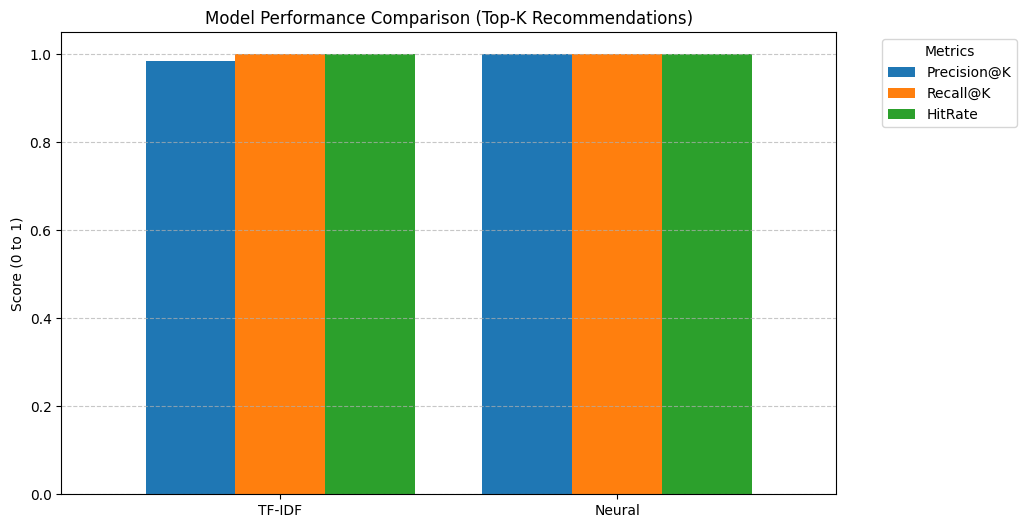

In [13]:
# Evaluate models using the corrected evaluate_model
tfidf_metrics = evaluate_model(recommend_tfidf)
neural_metrics = evaluate_model(recommend_neural)

print("TF-IDF:", tfidf_metrics)
print("Neural:", neural_metrics)

# Create a DataFrame for plotting
metrics_df = pd.DataFrame([tfidf_metrics, neural_metrics], index=["TF-IDF", "Neural"])

# Plotting all three metrics in a grouped bar chart
ax = metrics_df.plot(kind="bar", figsize=(10,6), width=0.8)
plt.title("Model Performance Comparison (Top-K Recommendations)")
plt.ylabel("Score (0 to 1)")
plt.ylim(0, 1.05)  # Ensure the y-axis is 0-1
plt.xticks(rotation=0)
plt.legend(title="Metrics", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [15]:
import os
import shutil

os.makedirs("models", exist_ok=True)

# 1. Save TF-IDF vectorizer
joblib.dump(tfidf_vectorizer, "models/tfidf_vectorizer.pkl")
print("TF-IDF Vectorizer saved.")

# 2. Save TF-IDF matrix as sparse .npz
sparse.save_npz("models/tfidf_matrix.npz", tfidf_matrix_train)
print("TF-IDF Matrix saved as tfidf_matrix.npz.")

# 3. Save Neural embeddings
np.save("models/neural_embeddings.npy", train_embeddings)
print("Neural embeddings saved as neural_embeddings.npy.")

# 4. Save training DataFrame
joblib.dump(train_df, "models/train_dataframe.pkl")
print("Training DataFrame saved as train_dataframe.pkl.")

# 5. Save sentence-transformer model
embedding_model.save("models/sentence_transformer_model")
print("SentenceTransformer model saved successfully.")

# At the very end:
zip_path = "models.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive("models", "zip", "models")
print(f"Created {zip_path} ({os.path.getsize(zip_path)/(1024*1024):.1f} MB)")

TF-IDF Vectorizer saved.
TF-IDF Matrix saved as tfidf_matrix.npz.
Neural embeddings saved as neural_embeddings.npy.
Training DataFrame saved as train_dataframe.pkl.


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

SentenceTransformer model saved successfully.
Created models.zip (84.2 MB)
